# Data Preprocessing

In [64]:
# import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn 

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
import plotly.express as px

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import rand_score, adjusted_rand_score, adjusted_mutual_info_score, silhouette_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import make_scorer
from sklearn.model_selection import ParameterGrid
import scipy.cluster.hierarchy as shc
from sklearn.preprocessing import scale


In [65]:
# read the dataframe
df = pd.read_csv("OnlineNewsPopularity.csv", on_bad_lines='skip')

In [66]:
# get a feel for the data
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [67]:
# get dataframe values
print(df.shape)
df.describe()

(39644, 61)


,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,...,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,354.530471,10.398749,546.514731,0.548216,0.996469,0.689175,10.883690,3.293638,4.544143,1.249874,...,0.095446,0.756728,-0.259524,-0.521944,-0.107500,0.282353,0.071425,0.341843,0.156064,3395.380184
std,214.163767,2.114037,471.107508,3.520708,5.231231,3.264816,11.332017,3.855141,8.309434,4.107855,...,0.071315,0.247786,0.127726,0.290290,0.095373,0.324247,0.265450,0.188791,0.226294,11626.950749
min,8.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,1.000000
25%,164.000000,9.000000,246.000000,0.470870,1.000000,0.625739,4.000000,1.000000,1.000000,0.000000,...,0.050000,0.600000,-0.328383,-0.700000,-0.125000,0.000000,0.000000,0.166667,0.000000,946.000000
50%,339.000000,10.000000,409.000000,0.539226,1.000000,0.690476,8.000000,3.000000,1.000000,0.000000,...,0.100000,0.800000,-0.253333,-0.500000,-0.100000,0.150000,0.000000,0.500000,0.000000,1400.000000
75%,542.000000,12.000000,716.000000,0.608696,1.000000,0.754630,14.000000,4.000000,4.000000,1.000000,...,0.100000,1.000000,-0.186905,-0.300000,-0.050000,0.500000,0.150000,0.500000,0.250000,2800.000000
max,731.000000,23.000000,8474.000000,701.000000,1042.000000,650.000000,304.000000,116.000000,128.000000,91.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,1.000000,843300.000000


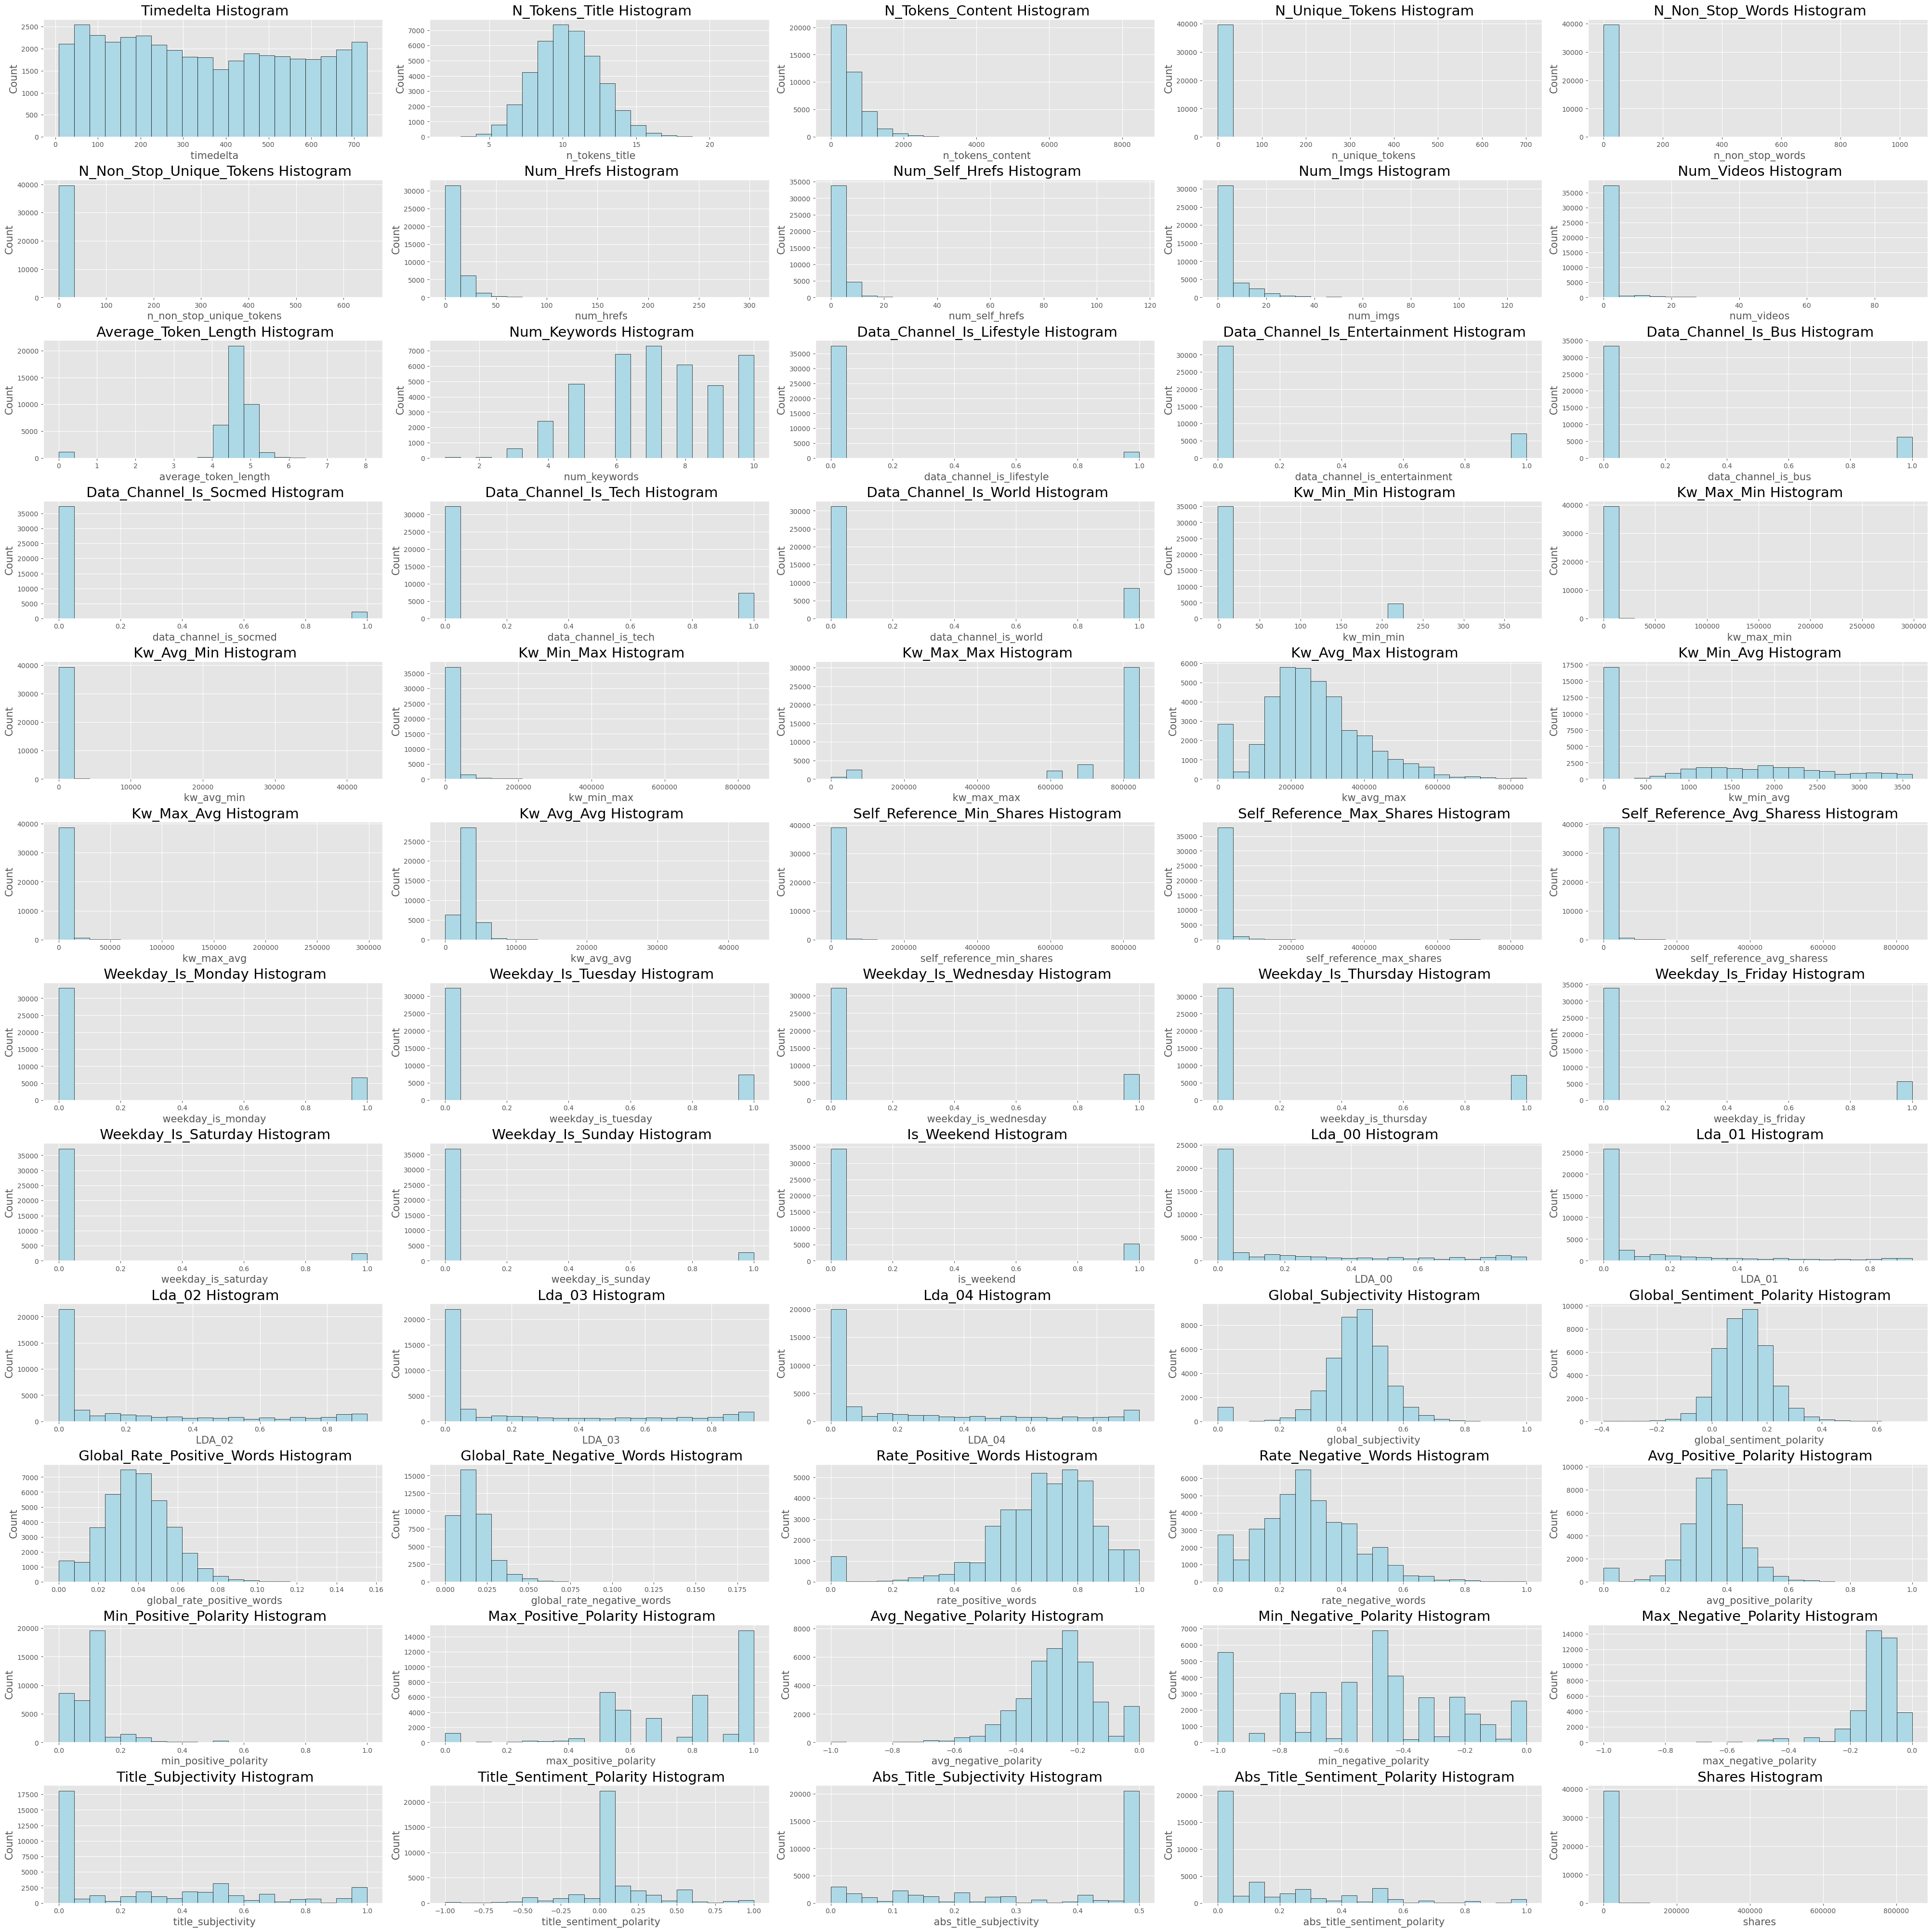

In [68]:
# Plot features and target variable distributions
plt.style.use('ggplot')
fig, axes = plt.subplots(nrows=12, ncols=5, squeeze=False, constrained_layout=True, figsize=(40,40))

for feature, ax in zip(df.columns[1:], axes.ravel()):

    # Plot histogram for feature
    plot = ax.hist(df[feature], bins=20, edgecolor='k', color='lightblue')

    # Add labels
    ax.set_ylabel('Count', fontsize=15)
    ax.set_xlabel(feature, fontsize=15)

    # Add title
    ax.set_title(f'{feature.title()} Histogram', fontsize=21)

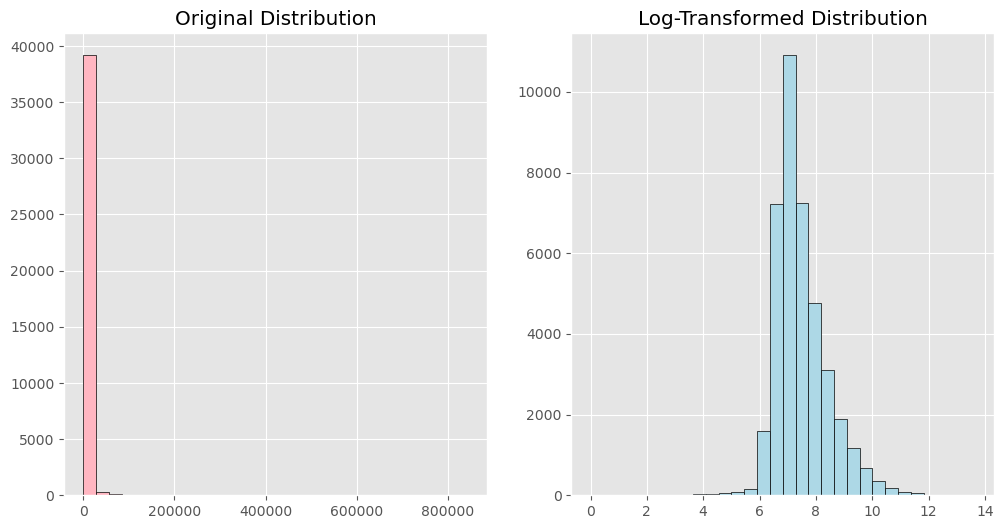

In [69]:
# Plot the original and log-transformed distributions to visualize the target variable
log_target = np.log(df[' shares'])
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.hist(df[' shares'], bins=30, color='lightpink', edgecolor='k')
plt.title('Original Distribution')

plt.subplot(1, 2, 2)
plt.hist(log_target, bins=30, color='lightblue', edgecolor='k')
plt.title('Log-Transformed Distribution')

plt.show()

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/1916148308.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  c = df.corr()


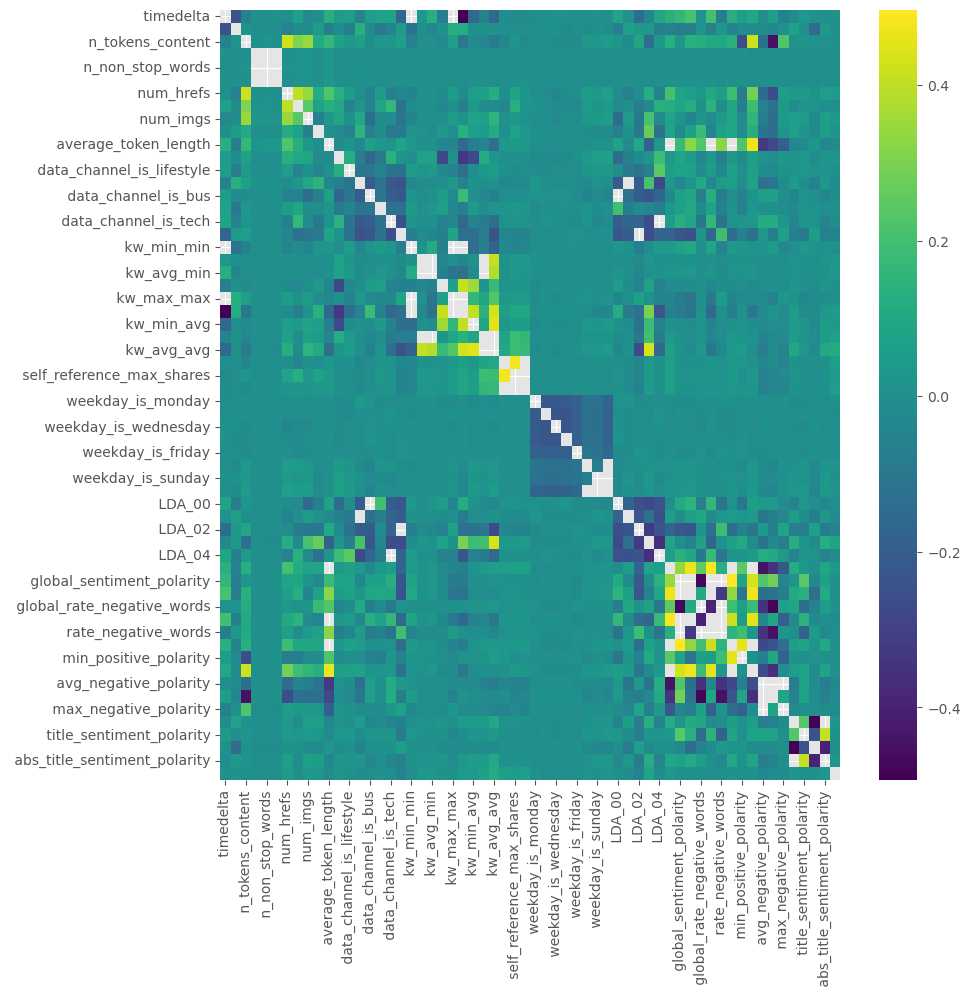

In [70]:
# get a feel for the feature correlations
c = df.corr() 
plt.figure(figsize=(10,10)) 
seaborn.heatmap(c, cmap='viridis', mask = (np.abs(c) >= 0.5)) 
plt.show()

In [71]:
# define popularity thresholds
def popularity(x)->str:
    if x <= 1400:
        return 'unpopular'
    return 'popular'

([0, 1], [Text(0, 0, 'unpopular'), Text(1, 0, 'popular')])

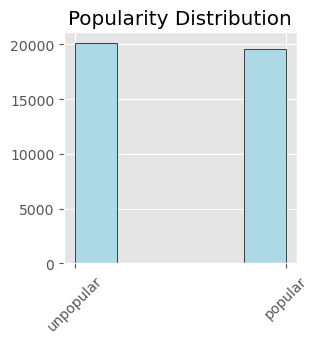

In [72]:
# apply the function to create column in dataframe
df['popularity'] = df[' shares'].apply(popularity)
plt.figure(figsize=(3, 3))

# check to see the distribution is even
plt.hist(df['popularity'], bins=5, color='lightblue', edgecolor='k')
plt.title('Popularity Distribution')
plt.xticks(rotation=45)

In [73]:
# check dataframe types
df.dtypes

url                               object
 timedelta                       float64
 n_tokens_title                  float64
 n_tokens_content                float64
 n_unique_tokens                 float64
                                  ...   
 title_sentiment_polarity        float64
 abs_title_subjectivity          float64
 abs_title_sentiment_polarity    float64
 shares                            int64
popularity                        object
Length: 62, dtype: object

In [74]:
# define features and target
features = df.columns[1:60]
target = df.columns[-2:]
features, target

(Index([' timedelta', ' n_tokens_title', ' n_tokens_content',
        ' n_unique_tokens', ' n_non_stop_words', ' n_non_stop_unique_tokens',
        ' num_hrefs', ' num_self_hrefs', ' num_imgs', ' num_videos',
        ' average_token_length', ' num_keywords', ' data_channel_is_lifestyle',
        ' data_channel_is_entertainment', ' data_channel_is_bus',
        ' data_channel_is_socmed', ' data_channel_is_tech',
        ' data_channel_is_world', ' kw_min_min', ' kw_max_min', ' kw_avg_min',
        ' kw_min_max', ' kw_max_max', ' kw_avg_max', ' kw_min_avg',
        ' kw_max_avg', ' kw_avg_avg', ' self_reference_min_shares',
        ' self_reference_max_shares', ' self_reference_avg_sharess',
        ' weekday_is_monday', ' weekday_is_tuesday', ' weekday_is_wednesday',
        ' weekday_is_thursday', ' weekday_is_friday', ' weekday_is_saturday',
        ' weekday_is_sunday', ' is_weekend', ' LDA_00', ' LDA_01', ' LDA_02',
        ' LDA_03', ' LDA_04', ' global_subjectivity',
        ' glo

# Fitting the Data to Clustering Models

## Base K-Means Cluster Models

In [189]:
# read the dataset
df = pd.read_csv("OnlineNewsPopularity.csv", on_bad_lines='skip')
df.columns = df.columns.str.strip()

# define popularity column
def popularity(x)->str:
    if x <= 1400:
        return 'unpopular'
    return 'popular'
df['popularity'] = df['shares'].apply(popularity)

# define features and target
features = df.columns[1:60]
X = df[features]
y = df['shares']

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change fr

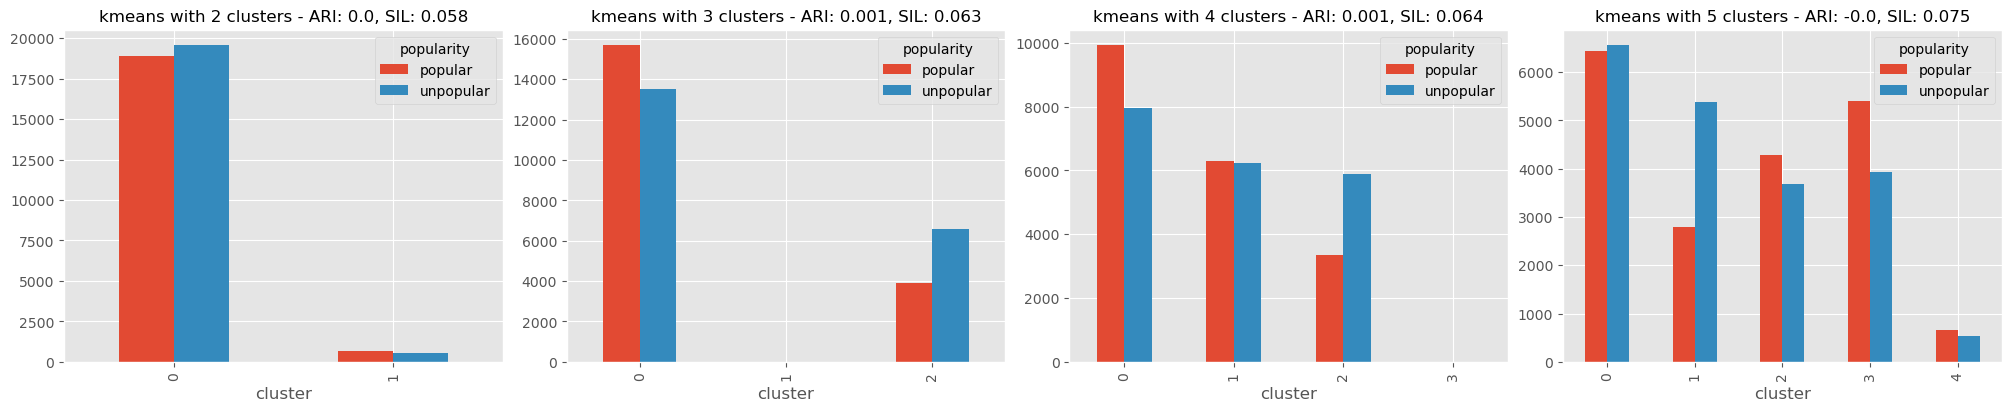

In [117]:
# define cluster range
n_clusters = [2, 3, 4, 5]

# plot cross tables for each n_cluster
X_scaled = StandardScaler().fit_transform(X)
fig, axes = plt.subplots(nrows=1, ncols=4, squeeze=False, constrained_layout=True, figsize=(20,4))
for i in range(len(n_clusters)):
    ax = axes[0, i]
    kmeans = KMeans(n_clusters=n_clusters[i])

    sil = silhouette_score(X_scaled, kmeans.fit_predict(X_scaled))
    sil = str(round(sil, 3))
    ari = adjusted_rand_score(y, kmeans.fit_predict(X_scaled))
    ari = str(round(ari, 3))

    df['cluster'] = kmeans.fit_predict(X_scaled)
    crosstb = pd.crosstab(df.cluster, df.popularity)
    barplot = crosstb.plot(kind='bar', ax=ax)

    ax.set_title(f"kmeans with {n_clusters[i]} clusters - ARI: {ari}, SIL: {sil}", fontsize=12)

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


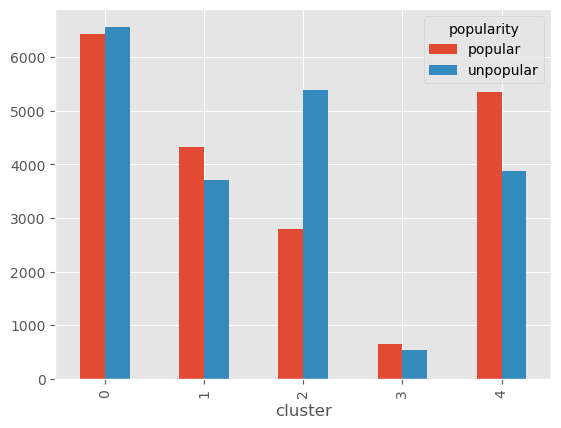

In [118]:
# refit and plot for 5 clusters in order to find the underpopulated cluster
kmeans = KMeans(n_clusters=5)
labels = kmeans.fit_predict(X_scaled)
df['cluster'] = labels

crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')

In [119]:
# save the dropped indices as a new df in order to analyze later
kmeans_indices_to_drop = df[labels == 3]

# drop the indices
indices_to_drop = df['cluster'] == 3
df = df[~indices_to_drop]

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change fr

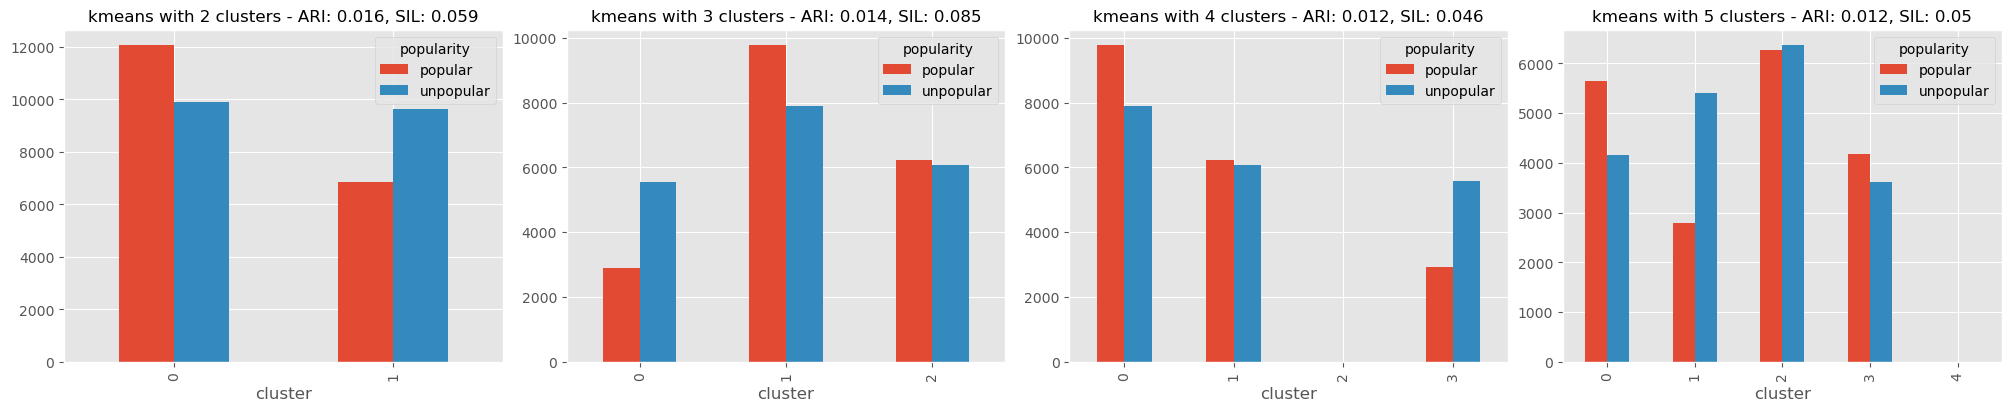

In [120]:
# define cluster range
n_clusters = [2, 3, 4, 5]

# set X and y for the updated dataset
X = df[features]
y = df['popularity']
X_scaled = StandardScaler().fit_transform(X)

# refit and replot the models
fig, axes = plt.subplots(nrows=1, ncols=4, squeeze=False, constrained_layout=True, figsize=(20,4))
for i in range(len(n_clusters)):
    ax = axes[0, i]
    kmeans = KMeans(n_clusters=n_clusters[i])

    sil = silhouette_score(X_scaled, kmeans.fit_predict(X_scaled))
    sil = str(round(sil, 3))
    ari = adjusted_rand_score(y, kmeans.fit_predict(X_scaled))
    ari = str(round(ari, 3))

    df['cluster'] = kmeans.fit_predict(X_scaled)
    crosstb = pd.crosstab(df.cluster, df.popularity)
    barplot = crosstb.plot(kind='bar', ax=ax)

    ax.set_title(f"kmeans with {n_clusters[i]} clusters - ARI: {ari}, SIL: {sil}", fontsize=12)

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


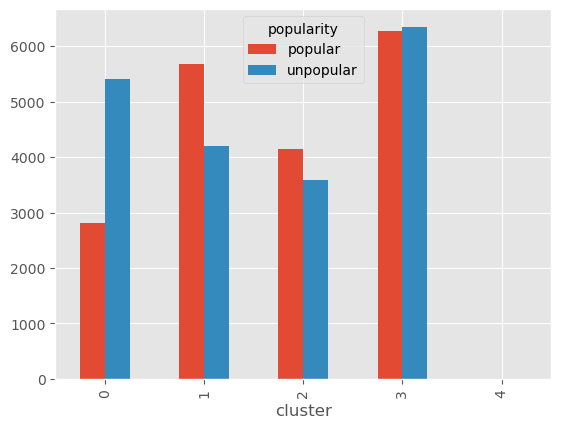

In [121]:
# refit and plot for 5 clusters in order to find the underpopulated cluster
kmeans = KMeans(n_clusters=5)
labels = kmeans.fit_predict(X_scaled)
df['cluster'] = labels

crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')

In [122]:
# drop the indices
indices_to_drop = df['cluster'] == 4
df = df[~indices_to_drop]

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


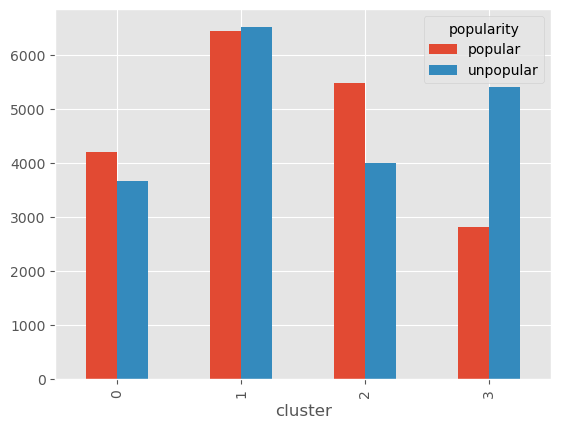

In [126]:
# set X and y for the updated dataset
X = df[features]
y = df['popularity']
X_scaled = StandardScaler().fit_transform(X)

# refit and plot for 5 clusters in order to find the underpopulated cluster
kmeans = KMeans(n_clusters=4)
labels = kmeans.fit_predict(X_scaled)
df['cluster'] = labels

crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')

In [125]:
# save clusters to analyze
kmeans_0 = df[df['cluster'] == 0]
kmeans_1 = df[df['cluster'] == 1]
kmeans_2 = df[df['cluster'] == 2]
kmeans_3 = df[df['cluster'] == 3]
kmeans_4 = df[df['cluster'] == 4]

## K-Means Cluster Gridsearch with Principal Component Analysis

In [185]:
# read the dataset
df = pd.read_csv("OnlineNewsPopularity.csv", on_bad_lines='skip')
df.columns = df.columns.str.strip()

# define popularity column
def popularity(x)->str:
    if x <= 1400:
        return 'unpopular'
    return 'popular'
df['popularity'] = df['shares'].apply(popularity)

# features and target
features = df.columns[1:60]
X = df[features]
y = df['shares']

In [169]:
# Scale the data
X_scaled = StandardScaler().fit_transform(X)

# Run a manual gridsearch for KMeans
best_score = -2
for n_components in range(3, 6):
    for n_clusters in range(6, 9):
        pca = PCA(n_components=n_components)
        kmeans = KMeans(n_clusters=n_clusters)

        X_pca = pca.fit_transform(X_scaled)
        labels = kmeans.fit_predict(X_pca)

        score = adjusted_rand_score(y, labels)
        if score > best_score:
            best_score = score
            best_n_components = n_components
            best_n_clusters = n_clusters
            best_labels = labels

# Define what the gridsearch found as the best model
X_pca = PCA(n_components=best_n_components).fit_transform(X_scaled)
best_kmeans = KMeans(n_clusters=best_n_clusters)
best_kmeans.fit_transform(X_pca)

# Score and print the best model
sil_score = silhouette_score(X_pca, best_labels)
rand_score = adjusted_rand_score(y, best_labels)
print(f"For {best_n_components} principal components and {best_n_clusters} clusters, we get a rand score of {rand_score} and a silhouette score of {sil_score}")
        

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change fr

For 4 principal components and 7 clusters, we get a rand score of 0.0013406161552888614 and a silhouette score of 0.2544916066627087


Text(0.5, 1.0, '4 component pca kmeans with 7 clusters - ARI: 0.0013406161552888614, SIL: 0.2544916066627087')

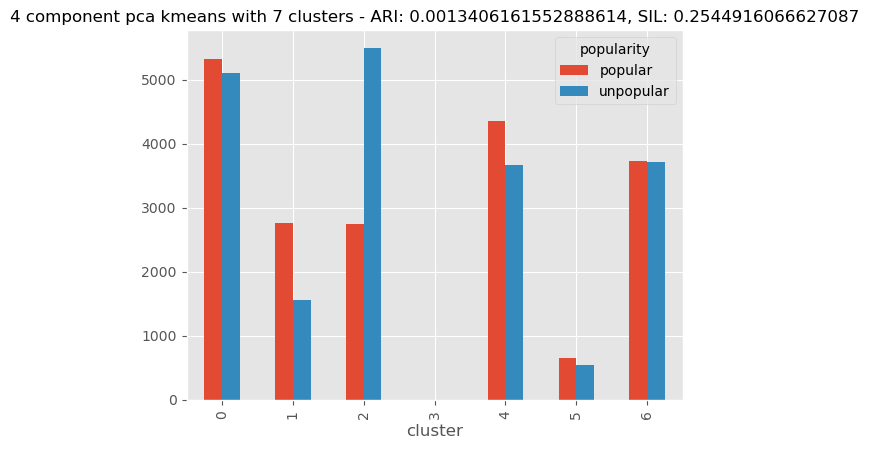

In [170]:
# plot the cross table of the best found model
df['cluster'] = best_labels
crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')
plt.title(f"{best_n_components} component pca kmeans with {best_n_clusters} clusters - ARI: {rand_score}, SIL: {sil_score}", fontsize=12)

In [171]:
# save rows to analyze later
pca_grid_indices_to_drop = df[labels == 3]

# drop the rows from the low populated cluster
drop_rows = df['cluster'] == 3
df = df[~drop_rows]

In [172]:
# redefine X and y according to the updated dataframe
X = df[features]
y = df['popularity']
X_scaled = StandardScaler().fit_transform(X)

# rerun the gridsearch
best_score = -2
for n_components in range(3, 5):
    for n_clusters in range(6, 9):
        pca = PCA(n_components=n_components)
        kmeans = KMeans(n_clusters=n_clusters)

        X_pca = pca.fit_transform(X_scaled)
        labels = kmeans.fit_predict(X_pca)

        score = adjusted_rand_score(y, labels)
        if score > best_score:
            best_score = score
            best_n_components = n_components
            best_n_clusters = n_clusters
            best_labels = labels

# Define what the gridsearch found as the best model
X_pca = PCA(n_components=best_n_components).fit_transform(X_scaled)
best_kmeans = KMeans(n_clusters=best_n_clusters)
best_kmeans.fit_transform(X_pca)

# Score and print the best model
sil_score = silhouette_score(X_pca, best_labels)
rand_score = adjusted_rand_score(y, best_labels)
print(f"For {best_n_components} principal components and {best_n_clusters} clusters, we get a rand score of {rand_score} and a silhouette score of {sil_score}")

/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change fr

For 4 principal components and 6 clusters, we get a rand score of 0.014226194264297321 and a silhouette score of 0.23876787176232794


/Users/<user>/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


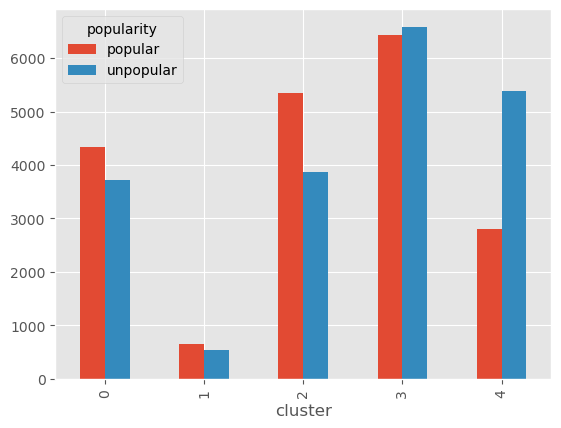

In [173]:
# set X and y for the updated dataset
X = df[features]
y = df['popularity']
X_scaled = StandardScaler().fit_transform(X)

# refit and plot for 5 clusters in order to find the underpopulated cluster
kmeans = KMeans(n_clusters=5)
labels = kmeans.fit_predict(X_scaled)
df['cluster'] = labels

crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')

In [174]:
# save the rows for each cluster to analyze
grid_0 = df[labels == 0]
grid_1 = df[labels == 1]
grid_2 = df[labels == 2]
grid_3 = df[labels == 3]
grid_4 = df[labels == 4]

<Figure size 640x480 with 0 Axes>

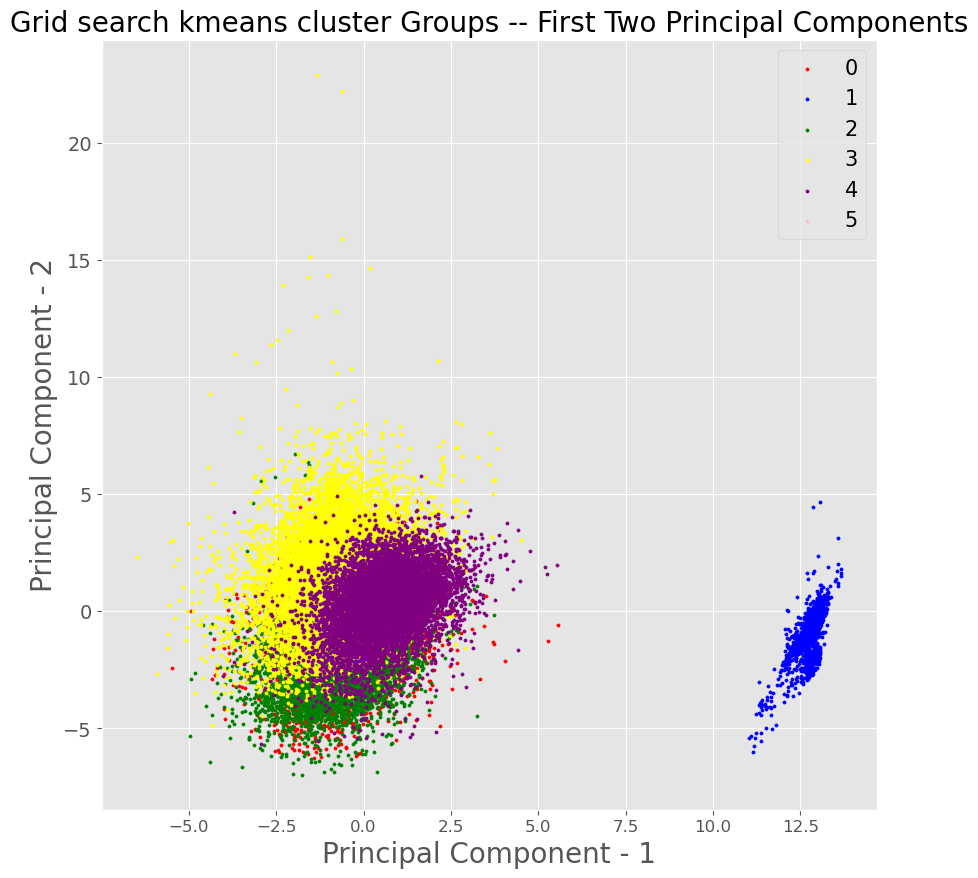

In [175]:
# define a pca dataframe
pca_ = PCA(n_components=best_n_components).fit_transform(X_scaled)
pca_df = pd.DataFrame(data = pca_
             , columns = ['principal component 1', 'principal component 2', 'principal component 3', 'principal component 4'])
pca_df = pca_df[['principal component 1', 'principal component 2']]

# plot the results of the best found PCA and best found clusters
plt.figure()
plt.figure(figsize=(10,10))
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Principal Component - 1',fontsize=20)
plt.ylabel('Principal Component - 2',fontsize=20)
plt.title("Grid search kmeans cluster Groups -- First Two Principal Components",fontsize=20)
targets = range(0, 6)
colors = ['r','b', 'green', 'yellow', 'purple', 'pink']

for target, color in zip(targets,colors):
    indicesToKeep = pca_df[labels == target]
    plt.scatter(x=indicesToKeep['principal component 1']
               , y=indicesToKeep['principal component 2'], c = color, s = 5, alpha=1)

plt.legend(targets,prop={'size': 15})
plt.show()

In [176]:
# save the PCA to analyze
kmeans_grid_pca = pca_

## Agglomerative Clustering

In [105]:
# read the dataset
df = pd.read_csv("OnlineNewsPopularity.csv", on_bad_lines='skip')
df.columns = df.columns.str.strip()

# define popularity column
def popularity(x)->str:
    if x <= 1400:
        return 'unpopular'
    return 'popular'
df['popularity'] = df['shares'].apply(popularity)

# features and target
features = df.columns[1:60]
X = df[features]
y = df['shares']

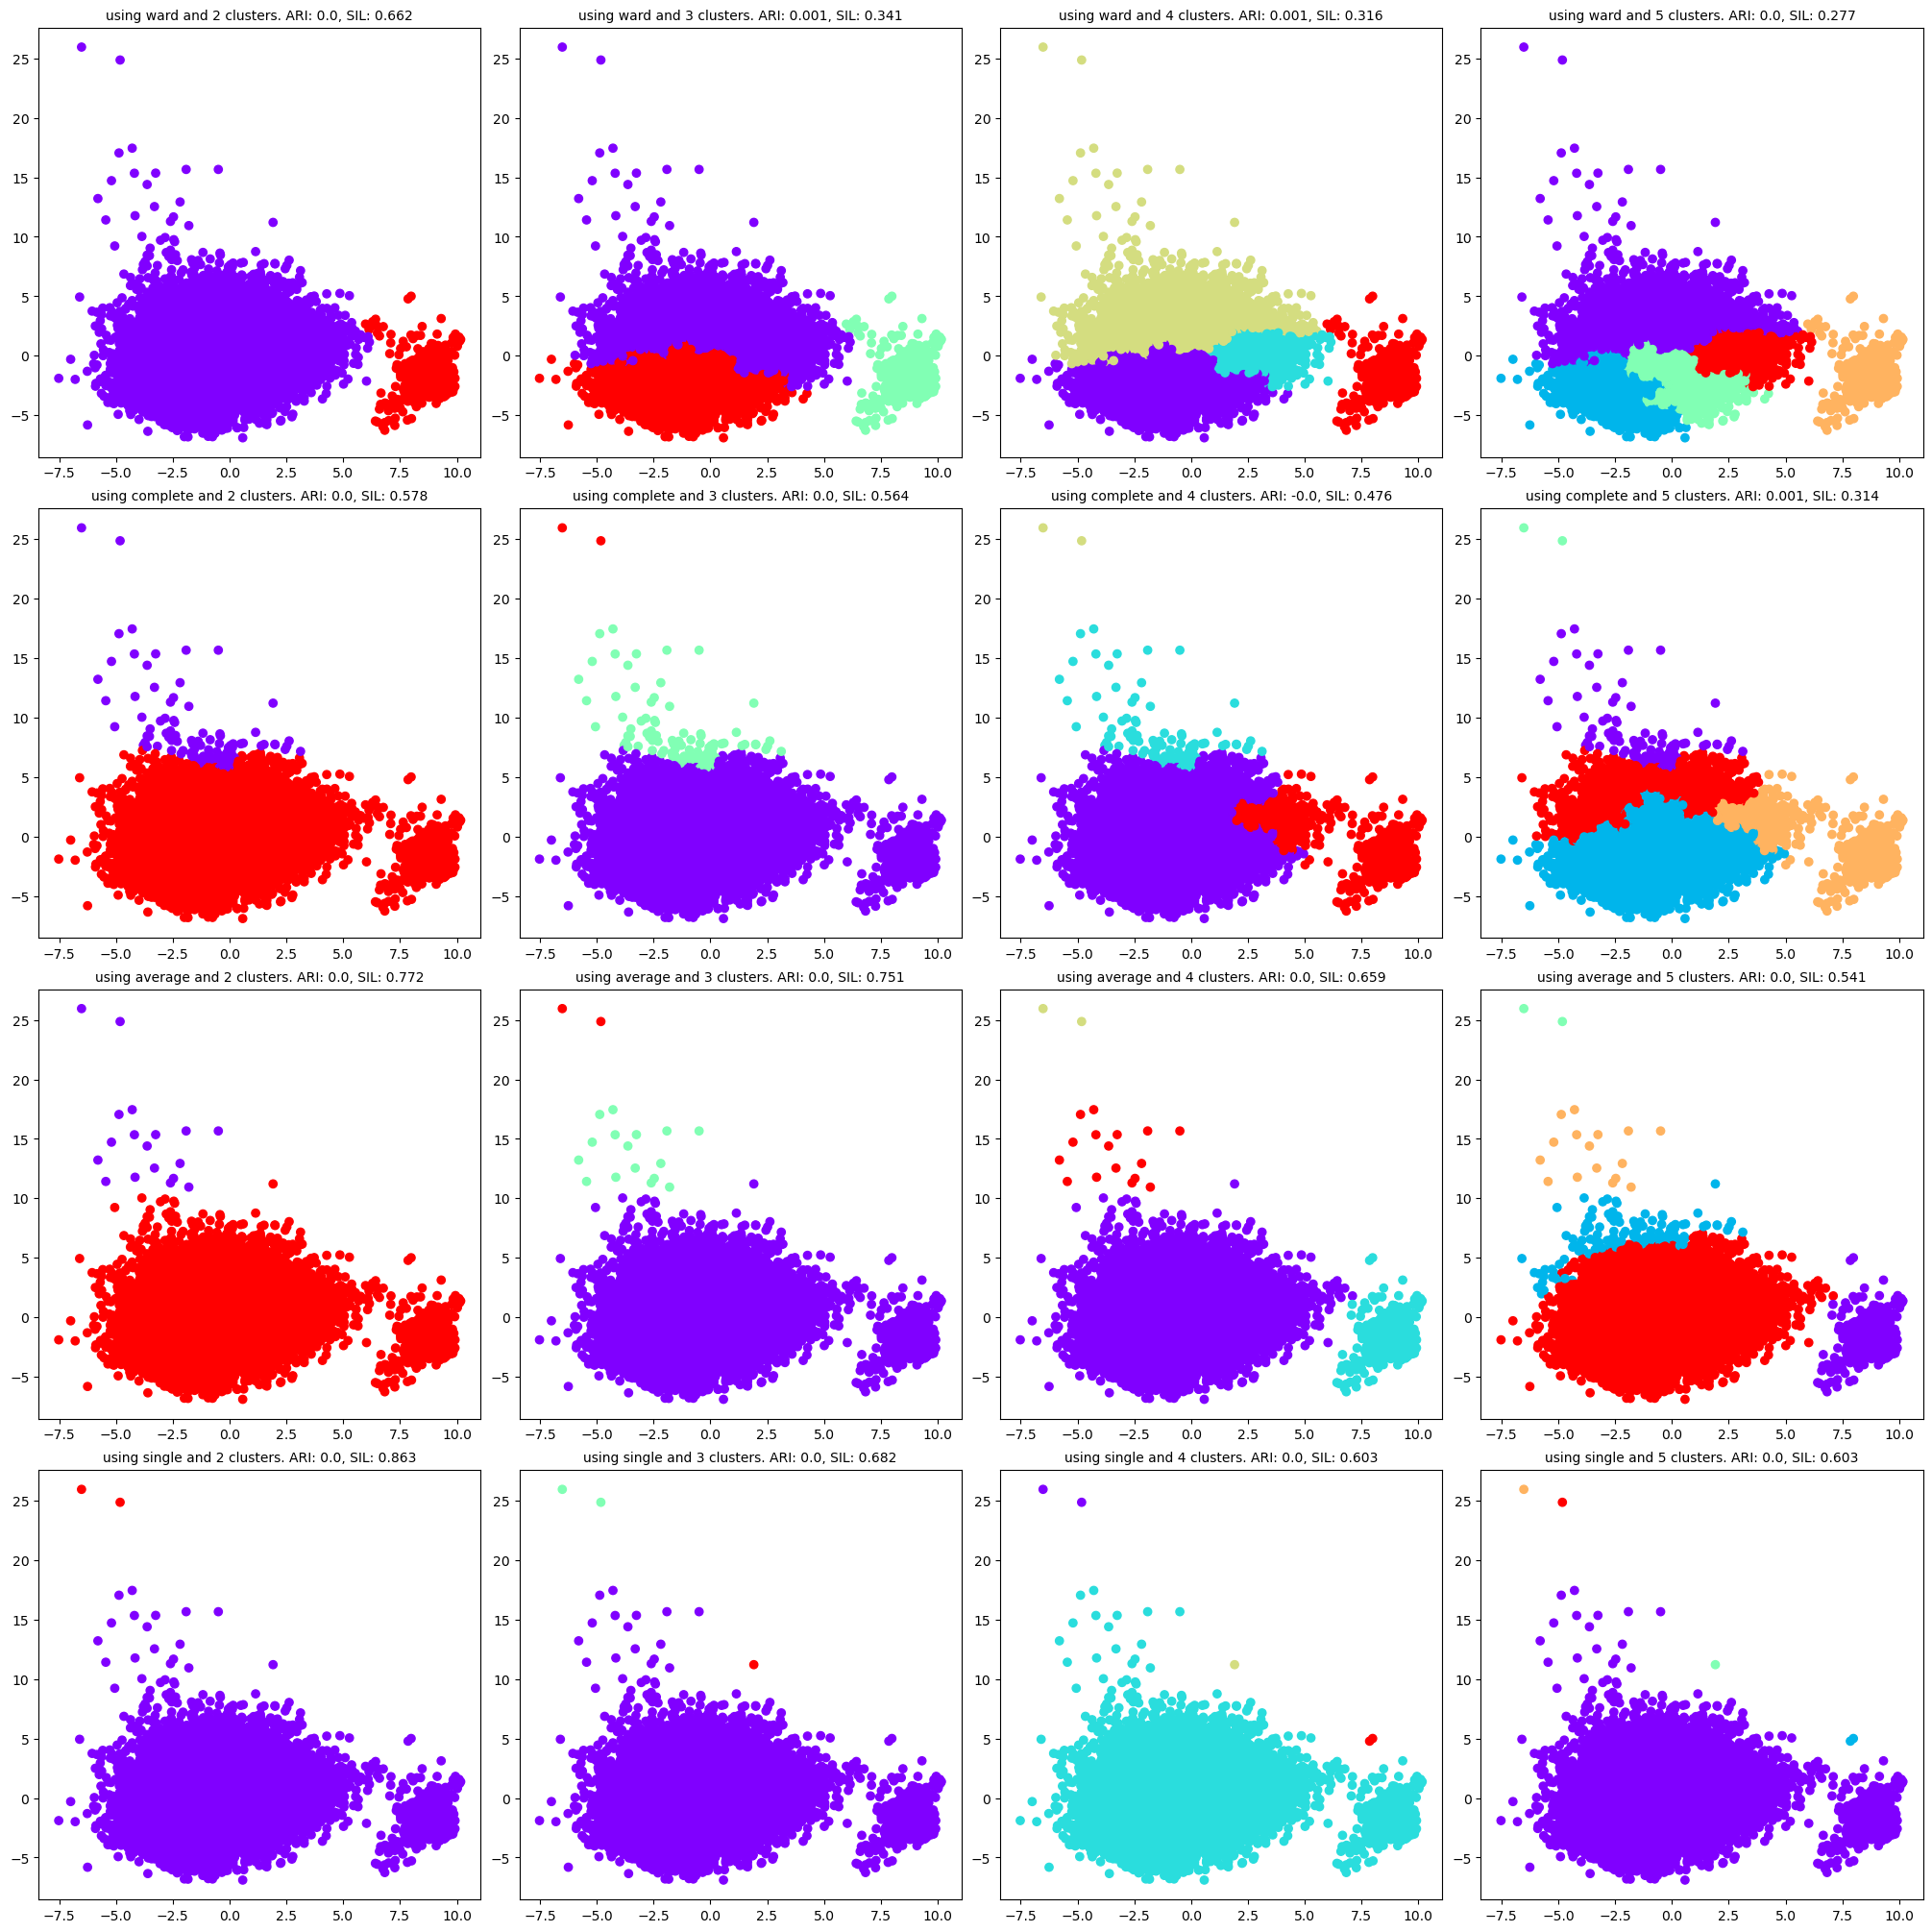

In [ ]:
# define the range of n_clusters and linkages
n_clusters = range(2, 6)
linkage = ['ward', 'complete', 'average', 'single']

# plot the agglomerative clustering with 2 component PCA across n_clusters and linkage
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components = 2)
X_principal = pca.fit_transform(X_scaled)
X_principal = pd.DataFrame(X_principal)
X_principal.columns = ['P1', 'P2']

fig, axes = plt.subplots(nrows=4, ncols=4, squeeze=False, constrained_layout=True, figsize=(20,20))

for i in range(len(linkage)):
    for j in range(len(n_clusters)):

        ax = axes[i, j]
        ac = AgglomerativeClustering(n_clusters=n_clusters[j], linkage=linkage[i])

        sil = silhouette_score(X_principal, ac.fit_predict(X_principal))
        sil = str(round(sil, 3))
        ari = adjusted_rand_score(y, ac.fit_predict(X_principal))
        ari = str(round(ari, 3))

        ax.scatter(X_principal['P1'], X_principal['P2'], c = ac.fit_predict(X_principal), cmap='rainbow')
        ax.set_title(f"using {linkage[i]} and {n_clusters[j]} clusters. ARI: {ari}, SIL: {sil}", fontsize=10)


In [109]:
X_scaled = StandardScaler().fit_transform(X)

# define and run a gridsearch to find the best n_components and n_clusters for the cluster model
best_score = -2
for n_components in range(5, 6):
    for n_clusters in range(4, 5):
        linkage = 'ward'
        pca = PCA(n_components=n_components)
        ac = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage)

        X_pca = pca.fit_transform(X_scaled)
        labels = ac.fit_predict(X_pca)

        score = adjusted_rand_score(y, labels)

        if score > best_score:
            best_score = score
            best_n_components = n_components
            best_n_clusters = n_clusters
            best_labels = labels

X_pca = PCA(n_components=best_n_components).fit_transform(X_scaled)
best_agg = AgglomerativeClustering(n_clusters=best_n_clusters, linkage='ward')
best_agg.fit_predict(X_pca)

sil_score = silhouette_score(X_pca, best_labels)
rand_score = adjusted_rand_score(y, best_labels)
print(f"For {best_n_components} principal components and {best_n_clusters} clusters, we get a rand score of {rand_score} and a silhouette score of {sil_score}")

For 5 principal components and 4 clusters, we get a rand score of 0.0005658034072353943 and a silhouette score of 0.19951913441150437


In [110]:
# saving the indices for each cluster
agg_0 = df[best_labels == 0]
agg_1 = df[best_labels == 1]
agg_2 = df[best_labels == 2]
agg_3 = df[best_labels == 3]

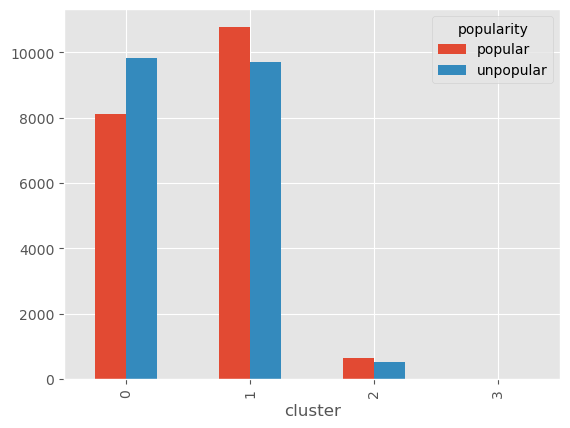

In [111]:
# plot the cross table of the best found model
df['cluster'] = best_labels
crosstb = pd.crosstab(df.cluster, df.popularity)
barplot = crosstb.plot(kind='bar')

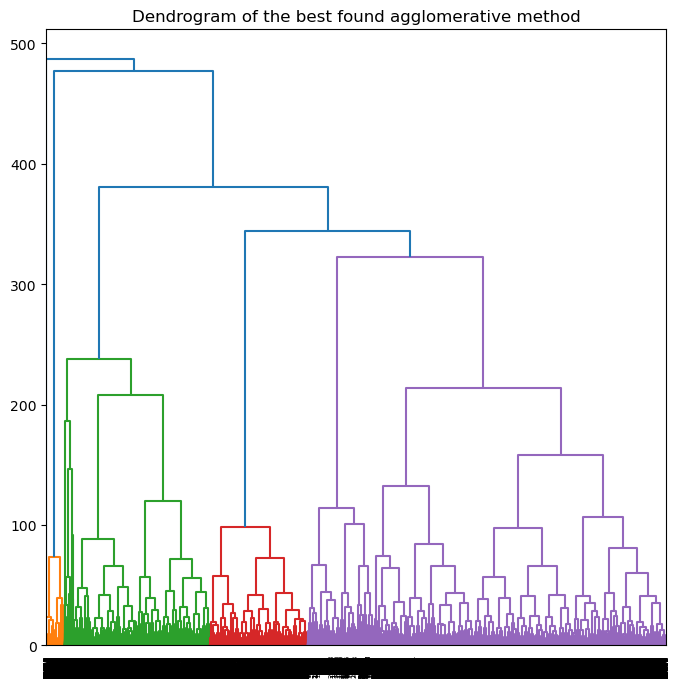

In [ ]:
plt.figure(figsize =(8, 8))
plt.title('Dendrogram of the best found agglomerative method')
Dendrogram = shc.dendrogram((shc.linkage(X_pca, method='ward')))


Text(0.5, 1.0, 'Agglomerative cluster with 5 PCA, 4 clusters -- ARI: 0.0005658034072353943, SIL: 0.19951913441150437')

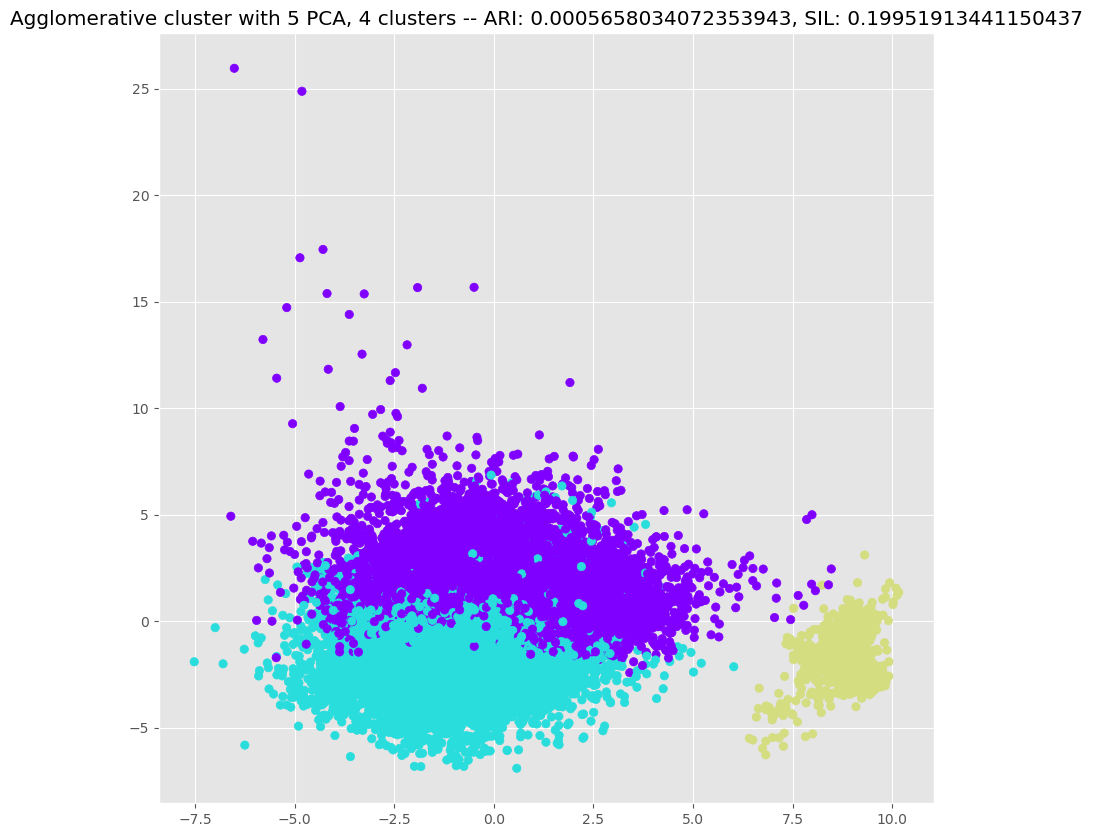

In [112]:
# define PCA dataframe
pca_df = pd.DataFrame(data = X_pca
             , columns = ['principal component 1', 'principal component 2', 'principal component 3', 'principal component 4', 'principal component 5'])
pca_df = pca_df[['principal component 1', 'principal component 2']]

ari = adjusted_rand_score(y, best_labels)
sil = silhouette_score(X_pca, best_labels)

# plot the PCA along with the clustering
plt.figure(figsize=(10, 10))
plt.scatter(pca_df['principal component 1'], pca_df['principal component 2'], c=best_labels, cmap='rainbow')
plt.title(f'Agglomerative cluster with 5 PCA, 4 clusters -- ARI: {ari}, SIL: {sil}')

## Analysis 

### Base Kmeans Clusters

In [127]:
# print the popularity values counts for each cluster in the base kmeans 
print("popularity count for Kmeans cluster 0 -- popular:", kmeans_0.popularity.value_counts()['popular'], 'unpopular:', kmeans_0.popularity.value_counts()['unpopular'])
print("popularity count for Kmeans cluster 1 -- popular:", kmeans_1.popularity.value_counts()['popular'], 'unpopular:', kmeans_1.popularity.value_counts()['unpopular'])
print("popularity count for Kmeans cluster 2 -- popular:", kmeans_2.popularity.value_counts()['popular'], 'unpopular:', kmeans_2.popularity.value_counts()['unpopular'])
print("popularity count for Kmeans cluster 3 -- popular:", kmeans_3.popularity.value_counts()['popular'], 'unpopular:', kmeans_2.popularity.value_counts()['unpopular'])


popularity count for Kmeans cluster 0 -- popular: 2589 unpopular: 5146
popularity count for Kmeans cluster 1 -- popular: 5842 unpopular: 5987
popularity count for Kmeans cluster 2 -- popular: 3735 unpopular: 3275
popularity count for Kmeans cluster 3 -- popular: 4476 unpopular: 3275


/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/1348458463.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_3 = (kmeans_3-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/1348458463.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_3 = (kmeans_3-df.mean())/df.std()


<Axes: >

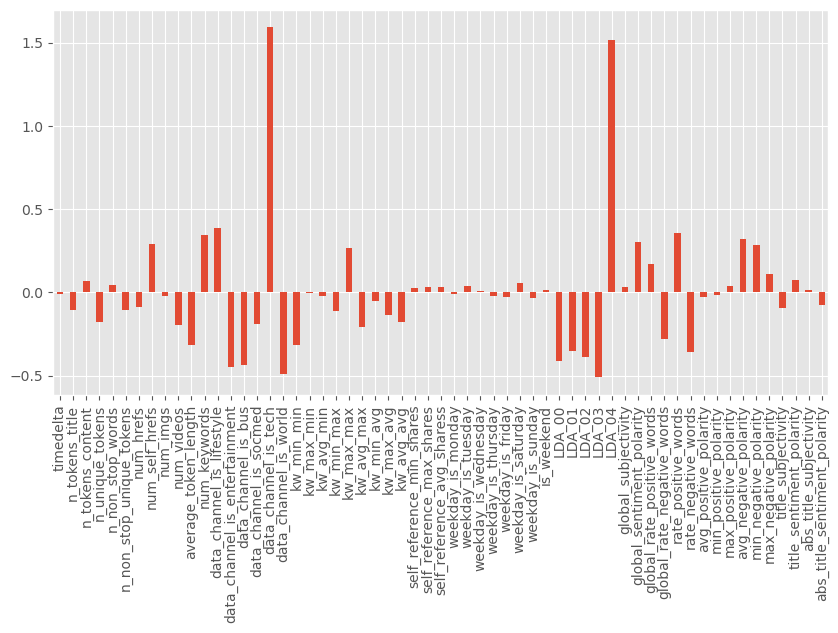

In [135]:
# standardize and analyze the cluster with the highest percentage of popular articles
compare_kmeans_3 = (kmeans_3-df.mean())/df.std()
compare_kmeans_3[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3817493088.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_1 = (kmeans_1-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3817493088.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_1 = (kmeans_1-df.mean())/df.std()


<Axes: >

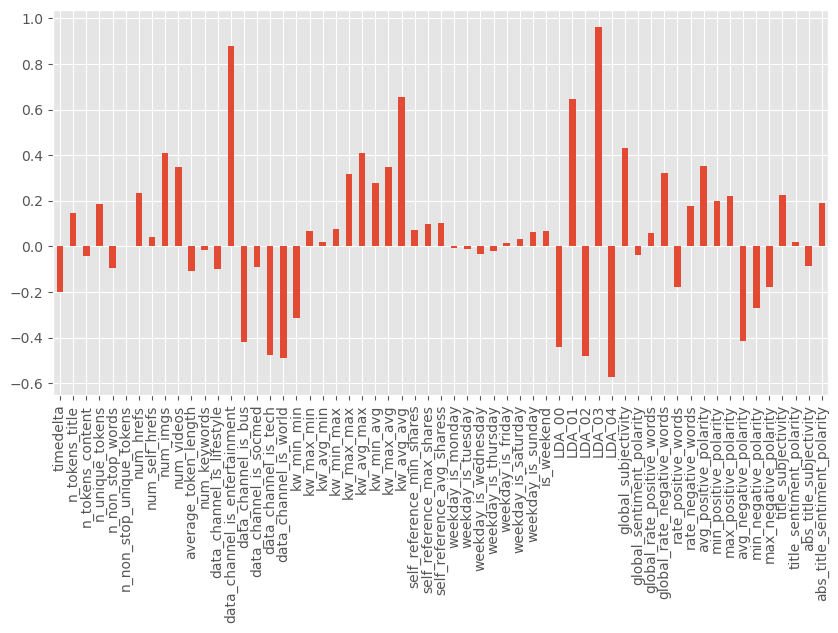

In [136]:
# standardize and analyze a "normal" cluster
compare_kmeans_1 = (kmeans_1-df.mean())/df.std()
compare_kmeans_1[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3193782933.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_2 = (kmeans_2-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3193782933.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_2 = (kmeans_2-df.mean())/df.std()


<Axes: >

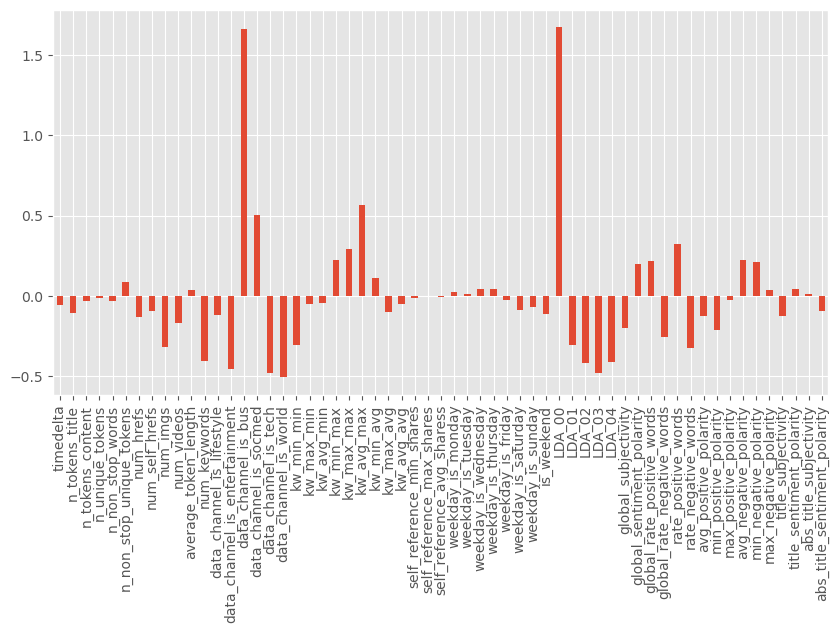

In [137]:
# standardize and analyze a "normal cluster"
compare_kmeans_2 = (kmeans_2-df.mean())/df.std()
compare_kmeans_2[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/2383694597.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_0 = (kmeans_0-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/2383694597.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_0 = (kmeans_0-df.mean())/df.std()


<Axes: >

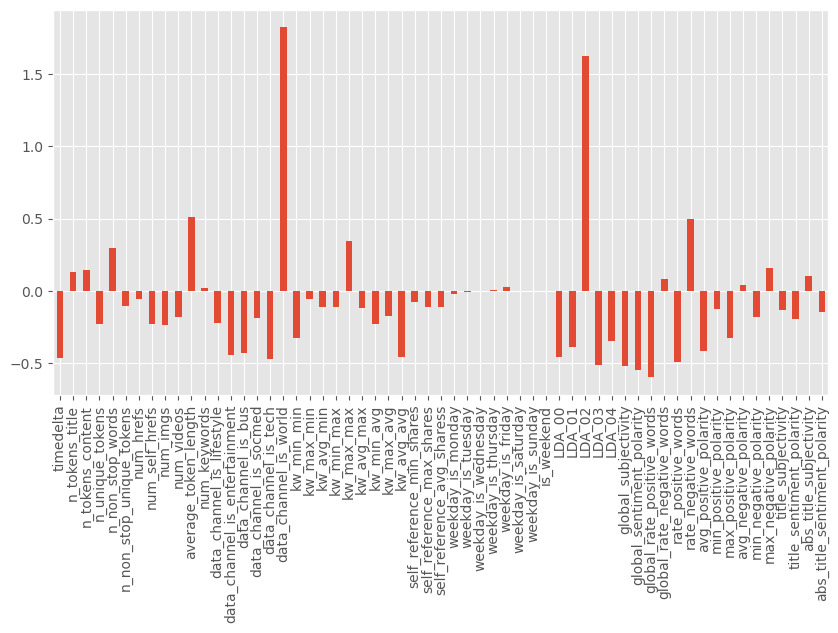

In [138]:
# standardize and analyze the cluster with the highest percentage of unpopular articles
compare_kmeans_0 = (kmeans_0-df.mean())/df.std()
compare_kmeans_0[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/4006948198.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_indices_to_drop = (kmeans_indices_to_drop-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/4006948198.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_kmeans_indices_to_drop = (kmeans_indices_to_drop-df.mean())/df.std()


<Axes: >

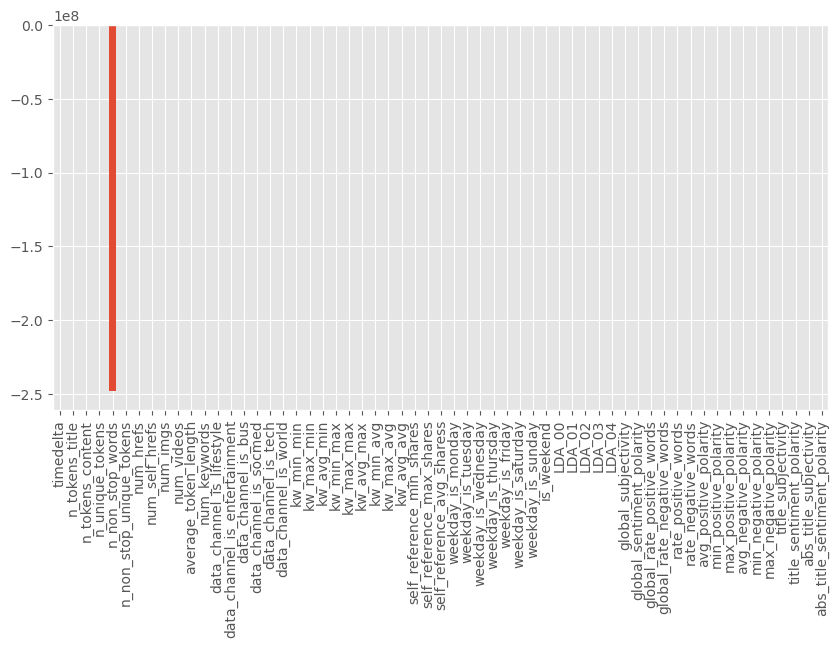

In [134]:
# standardize and analyze the articles dropped in the Kmeans model
compare_kmeans_indices_to_drop = (kmeans_indices_to_drop-df.mean())/df.std()
compare_kmeans_indices_to_drop[features].mean().plot(kind='bar', figsize=(10, 5))

### Kmeans Gridsearch Clusters

In [177]:
# print the popularity value counts
print("popularity count for pca grid cluster 0 -- popular:", grid_0.popularity.value_counts()['popular'], 'unpopular:', grid_0.popularity.value_counts()['unpopular'])
print("popularity count for pca grid cluster 1 -- popular:", grid_1.popularity.value_counts()['popular'], 'unpopular:', grid_1.popularity.value_counts()['unpopular'])
print("popularity count for pca grid cluster 2 -- popular:", grid_2.popularity.value_counts()['popular'], 'unpopular:', grid_2.popularity.value_counts()['unpopular'])
print("popularity count for pca grid cluster 3 -- popular:", grid_3.popularity.value_counts()['popular'], 'unpopular:', grid_3.popularity.value_counts()['unpopular'])
print("popularity count for pca grid cluster 4 -- popular:", grid_4.popularity.value_counts()['popular'], 'unpopular:', grid_4.popularity.value_counts()['unpopular'])

popularity count for pca grid cluster 0 -- popular: 4341 unpopular: 3710
popularity count for pca grid cluster 1 -- popular: 650 unpopular: 531
popularity count for pca grid cluster 2 -- popular: 5344 unpopular: 3871
popularity count for pca grid cluster 3 -- popular: 6431 unpopular: 6584
popularity count for pca grid cluster 4 -- popular: 2795 unpopular: 5386


/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3850860023.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_4 = (grid_4-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3850860023.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_4 = (grid_4-df.mean())/df.std()


<Axes: >

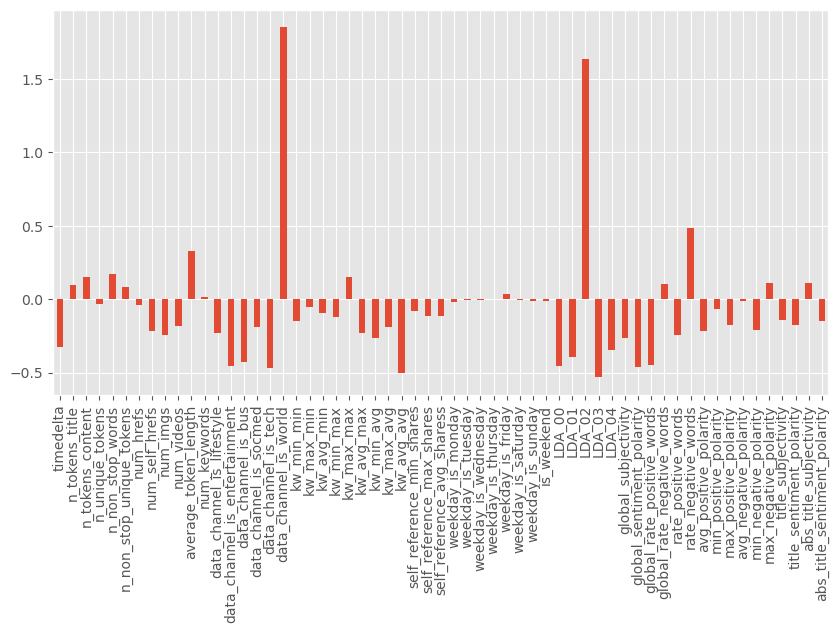

In [178]:
# standardize and analyze the cluster with the highest percentage of unpopular articles
compare_grid_4 = (grid_4-df.mean())/df.std()
compare_grid_4[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3756888600.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_1 = (grid_1-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/3756888600.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_1 = (grid_1-df.mean())/df.std()


<Axes: >

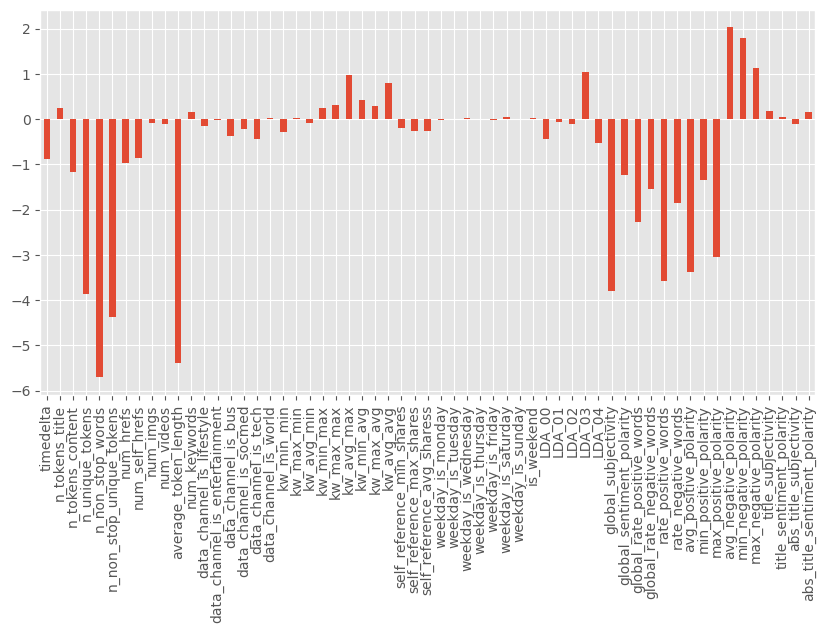

In [180]:
# standardize and analyze the cluster with the lowest count(also farthest away on the scatter plot)
compare_grid_1 = (grid_1-df.mean())/df.std()
compare_grid_1[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/1325145058.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_2 = (grid_2-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/1325145058.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_2 = (grid_2-df.mean())/df.std()


<Axes: >

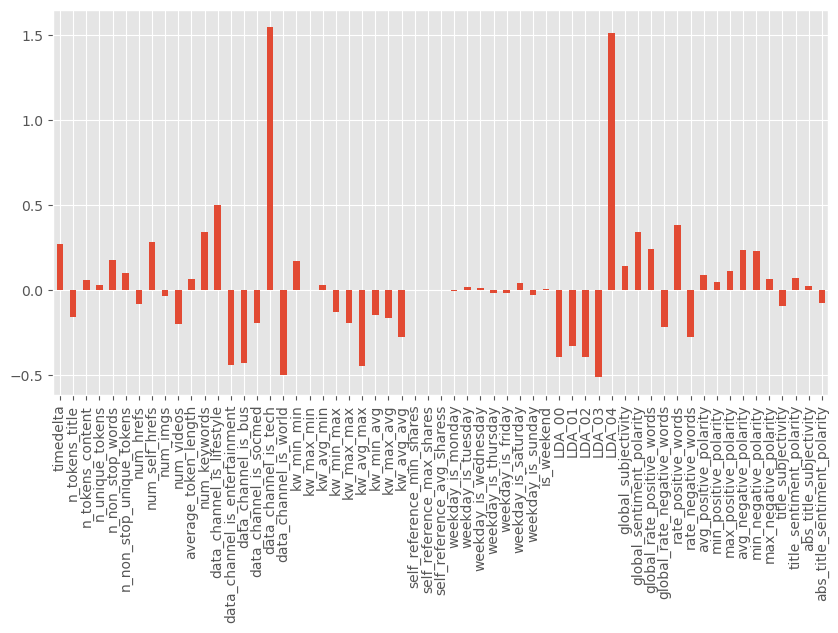

In [181]:
# standardize and analyze the cluster with the highest percentage of popular articles
compare_grid_2 = (grid_2-df.mean())/df.std()
compare_grid_2[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/2647524522.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_0 = (grid_0-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/2647524522.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_0 = (grid_0-df.mean())/df.std()


<Axes: >

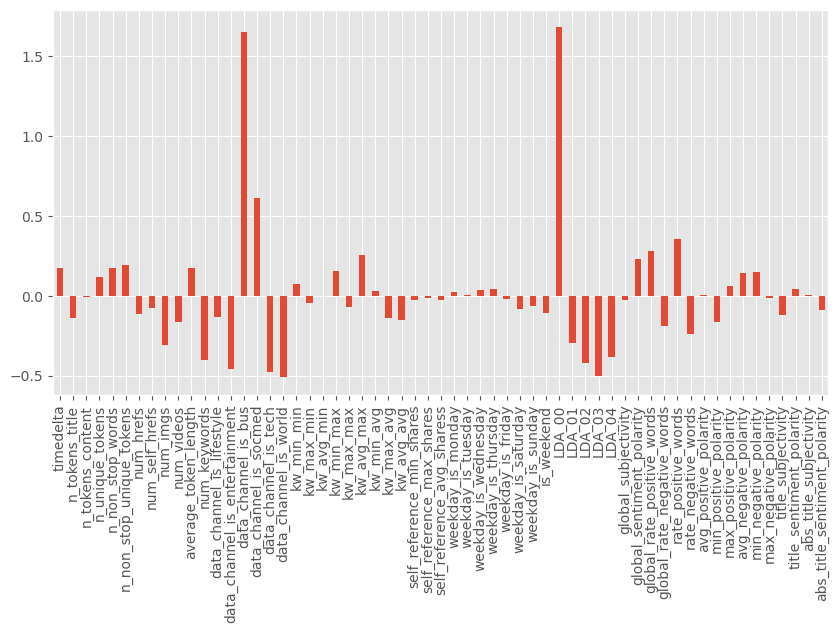

In [182]:
# standardize and analyze the cluster with a high percentage of popular articles
compare_grid_0 = (grid_0-df.mean())/df.std()
compare_grid_0[features].mean().plot(kind='bar', figsize=(10, 5))

/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/832407443.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_3 = (grid_3-df.mean())/df.std()
/var/folders/bj/dvfltst50f528xy6jgrpyhxc0000gn/T/ipykernel_80857/832407443.py:2: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  compare_grid_3 = (grid_3-df.mean())/df.std()


<Axes: >

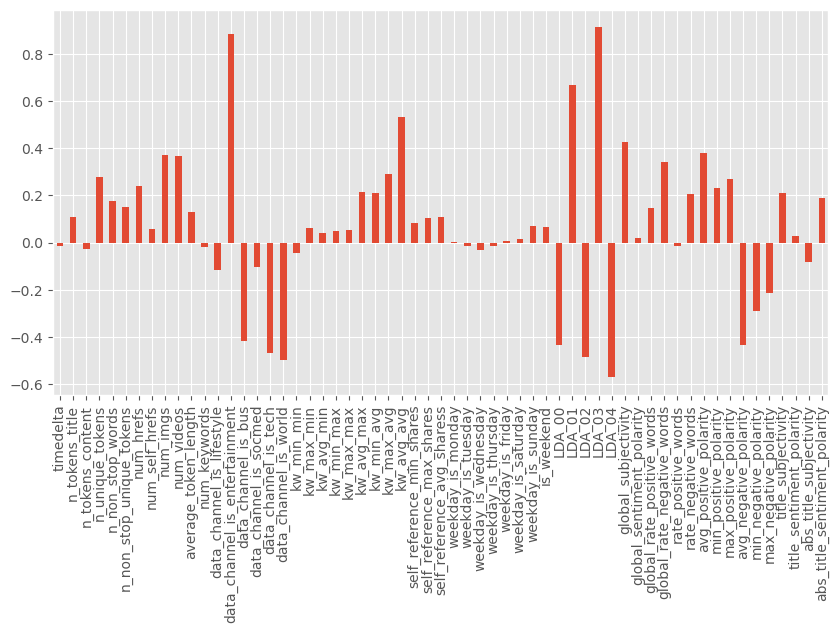

In [183]:
# standardize and analyze a "normal" cluster
compare_grid_3 = (grid_3-df.mean())/df.std()
compare_grid_3[features].mean().plot(kind='bar', figsize=(10, 5))

In [190]:
# defin the 4-component pca dataframe and analyze its relation to each feature
pca = PCA(n_components=4)
pca.fit_transform(X_scaled)

pd.set_option('display.max_columns', None)
data_scaled = pd.DataFrame(scale(df[features]),columns = features)
pd.DataFrame(pca.components_,columns=data_scaled.columns,index = ['PC-1','PC-2', 'PC-3', 'PC-4'])

,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,num_keywords,data_channel_is_lifestyle,data_channel_is_entertainment,data_channel_is_bus,data_channel_is_socmed,data_channel_is_tech,data_channel_is_world,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg,self_reference_min_shares,self_reference_max_shares,self_reference_avg_sharess,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday,is_weekend,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity
PC-1,-0.125091,0.042423,-0.057806,-0.277565,-0.355596,-0.302592,-0.081044,-0.073831,-0.004723,-0.029266,-0.330072,-0.015306,-0.032313,-0.012668,-0.026376,-0.025977,-0.040246,0.078102,-0.071929,-0.005347,-0.020115,0.026900,0.076153,0.095520,0.032907,0.008482,0.033070,-0.024334,-0.030410,-0.030799,-0.000199,0.003103,0.003237,0.001829,0.000170,-0.003834,-0.008840,-0.009383,-0.039575,-0.025456,0.071088,0.032729,-0.047438,-0.317666,-0.178411,-0.240032,-0.086824,-0.280176,-0.046421,-0.300490,-0.114715,-0.267085,0.171453,0.127959,0.118130,-0.019916,-0.028410,0.009302,-0.025874
PC-2,-0.204901,0.081131,0.091719,-0.001608,0.046002,-0.005120,0.116745,0.016703,0.109463,0.129142,0.049943,-0.061968,-0.043557,0.128372,-0.075180,-0.027028,-0.177668,0.033622,-0.200999,0.066799,0.033594,0.090648,0.215509,0.233616,0.149080,0.160075,0.236222,0.071793,0.102171,0.100586,-0.001415,-0.009767,-0.016020,-0.007329,0.009107,0.017234,0.023956,0.030316,-0.085430,0.073943,0.024540,0.193901,-0.200363,0.090233,-0.235702,-0.096612,0.281200,-0.206229,0.301443,0.065662,0.036312,0.056391,-0.257362,-0.281754,-0.044444,0.080411,-0.058370,-0.024115,0.064604
PC-3,-0.024219,-0.001288,-0.024351,-0.065934,-0.111170,-0.105003,0.062314,0.051962,0.087447,0.049039,-0.127437,0.014320,0.038066,0.031053,0.062271,0.042986,0.020645,-0.289840,-0.063297,0.171795,0.160056,0.097788,0.073175,0.181287,0.176141,0.255701,0.337191,0.094250,0.129291,0.128688,-0.009065,-0.000027,-0.006794,-0.004353,-0.015791,0.026229,0.027445,0.039362,0.082153,0.014673,-0.294546,0.189525,0.008060,0.036707,0.268723,0.152751,-0.198966,0.149514,-0.303115,0.048740,-0.025793,0.060280,0.094836,0.139623,-0.007006,0.122883,0.154969,-0.093635,0.139091
PC-4,0.061862,-0.008603,0.380662,-0.304732,-0.039764,-0.255921,0.282285,0.238601,0.274164,0.039571,-0.047790,0.217974,0.077441,0.054956,-0.197624,0.000921,0.111946,0.008480,0.077642,0.010064,0.021666,-0.129358,-0.081913,-0.232644,-0.093451,-0.023129,-0.064754,-0.077243,-0.036334,-0.074643,-0.015277,-0.020397,-0.039214,-0.029320,-0.026248,0.103309,0.097138,0.146800,-0.170173,0.017822,0.018340,-0.008167,0.131653,0.019211,0.026616,0.058725,0.041403,-0.024836,-0.012271,0.021328,-0.185053,0.184901,-0.031366,-0.191798,0.158070,0.086269,0.075035,-0.055753,0.098545
